<a href="https://colab.research.google.com/github/sangramshitole07/AML/blob/main/Feature_Select_Wrapper_Methods.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [31]:
# We import load_breast_cancer to get the classification dataset.
from sklearn.datasets import load_breast_cancer
# We import LogisticRegression to use as our core linear model for classification.
from sklearn.linear_model import LogisticRegression
# We import StandardScaler to scale features, ensuring that all variables contribute equally to the model.
from sklearn.preprocessing import StandardScaler
# We import SequentialFeatureSelector to perform forward or backward wrapper feature selection.
from sklearn.feature_selection import SequentialFeatureSelector
# We import Pipeline to neatly chain scaling, feature selection, and classification steps sequentially.
from sklearn.pipeline import Pipeline

#1)Forward feature Selections

In [32]:
# Load the classic Wisconsin breast cancer diagnostic dataset for binary classification
data = load_breast_cancer()

# X represents the feature matrix (input characteristics like radius, texture, etc.)
X = data.data

# y represents the target array (binary indicators for malignant or benign tumors)
y = data.target

In [4]:
print(X.shape)

(569, 30)


In [33]:
# Define a pipeline that standardizes features before passing them to logistic regression
# Why: Scale alignment is critical for logistic regression regularization and convergence
model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=5000))
])

# Instantiate the Sequential Feature Selector
# What: Wraps the model to iteratively find the 5 best features using forward selection based on cross-validated accuracy
selector = SequentialFeatureSelector(
    model,
    n_features_to_select=5,
    direction='forward',
    scoring='accuracy',
    cv=5
)

# Train the selector on the data to find the optimal features
selector.fit(X, y)

# Display the names of the 5 features selected by the forward selection strategy
print(data.feature_names[selector.get_support()])

['mean symmetry' 'concavity error' 'worst texture' 'worst perimeter'
 'worst smoothness']


#2)Backward feature elimination

In [34]:
# Instantiate the Sequential Feature Selector with backward elimination
# What: Starts with all features and iteratively removes the least useful feature until 5 are left
# Why: Backward elimination preserves feature interactions better than forward selection
selector = SequentialFeatureSelector(
    model,
    n_features_to_select=5,
    direction='backward',
    scoring='accuracy',
    cv=5
)

# Fit the backward elimination selector to determine the most stable 5 features
selector.fit(X, y)

# Print the names of the final selected features
print(data.feature_names[selector.get_support()])

['mean texture' 'mean concave points' 'worst area' 'worst smoothness'
 'worst concavity']


#3)Recursive Feature Selections

In [35]:
# Import RFE for recursive rank-based elimination
from sklearn.feature_selection import RFE

# Load the diagnostic breast cancer dataset
data = load_breast_cancer()
X = data.data
y = data.target

# Standardize the features so that coefficients directly represent feature importance
X_scaled = StandardScaler().fit_transform(X)

# Use a standard linear model to estimate feature weights via its coefficients
model = LogisticRegression(max_iter=5000)

# Instantiate RFE to recursively prune 1 feature at a time based on model coefficients
# Why: It helps us see a detailed importance ranking for every single feature
selector = RFE(
    estimator=model,
    n_features_to_select=5,
    step=1
)

# Fit the RFE selector
selector.fit(X_scaled, y)

# Output the selection status and importance rank for each feature
for name, selected, rank in zip(
    data.feature_names,
    selector.get_support(),
    selector.ranking_
):
    print(f"{name}:{selected}:{rank}")

mean radius:False:12
mean texture:False:14
mean perimeter:False:15
mean area:False:8
mean smoothness:False:23
mean compactness:False:10
mean concavity:False:13
mean concave points:False:3
mean symmetry:False:25
mean fractal dimension:False:20
radius error:True:1
texture error:False:22
perimeter error:False:9
area error:False:4
smoothness error:False:18
compactness error:False:6
concavity error:False:24
concave points error:False:21
symmetry error:False:17
fractal dimension error:False:16
worst radius:True:1
worst texture:True:1
worst perimeter:False:2
worst area:True:1
worst smoothness:False:7
worst compactness:False:26
worst concavity:False:5
worst concave points:True:1
worst symmetry:False:11
worst fractal dimension:False:19


using cross validation

In [36]:
# Import RFECV for automatic optimal feature count determination, and StratifiedKFold for balanced cv splits
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold

# Logistic regression will estimate our feature coefficients
model = LogisticRegression(max_iter=5000)

# What: Set up cross-validation with stratification
# Why: Stratification maintains target class distribution ratios across folds, yielding robust validation scores
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# RFECV automatically discovers the ideal number of features by maximizing cross-validated accuracy
selector = RFECV(
    estimator=model,
    step=1,
    cv=cv,
    scoring='accuracy',
    min_features_to_select=1
)

# Fit on standardized inputs
selector.fit(X_scaled, y)

# Print evaluation metrics and selected features
print("optimal number of features : ", selector.n_features_)
print("selected features : ", data.feature_names[selector.support_])

# Print details for every single feature
for name, selected, rank in zip(
    data.feature_names,
    selector.get_support(),
    selector.ranking_
):
    print(f"{name}:{selected}:{rank}")

optimal number of features :  23
selected features :  ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean compactness' 'mean concavity' 'mean concave points' 'radius error'
 'perimeter error' 'area error' 'smoothness error' 'compactness error'
 'symmetry error' 'fractal dimension error' 'worst radius' 'worst texture'
 'worst perimeter' 'worst area' 'worst smoothness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']
mean radius:True:1
mean texture:True:1
mean perimeter:True:1
mean area:True:1
mean smoothness:False:5
mean compactness:True:1
mean concavity:True:1
mean concave points:True:1
mean symmetry:False:7
mean fractal dimension:False:2
radius error:True:1
texture error:False:4
perimeter error:True:1
area error:True:1
smoothness error:True:1
compactness error:True:1
concavity error:False:6
concave points error:False:3
symmetry error:True:1
fractal dimension error:True:1
worst radius:True:1
worst texture:True:1
worst perimeter:True:1


#4)Embedded Method


In [37]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler

# Load diabetes regression dataset to demonstrate regularization feature selection
data = load_diabetes()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# Standardize variables to avoid bias in regularization penalties
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# What: Use Lasso (L1) with built-in cross-validation to search for optimal penalty (alpha)
# Why: Lasso naturally drives non-important feature coefficients to zero, achieving automatic embedded selection
lasso = LassoCV(cv=5, random_state=42, max_iter=10000)
lasso.fit(X_scaled, y)

# Extract coefficients into a clean pandas series
coefficients = pd.Series(
    lasso.coef_,
    index=X.columns
)

# Identify non-zero coefficients (our selected features)
selected_features = coefficients[coefficients.abs() > 1e-6]

print("Best alpha :", lasso.alpha_)
print("Selected Features :", selected_features)

Best alpha : 0.07891843500595844
Selected Features : age    -0.308921
sex   -11.225046
bmi    24.816849
bp     15.271304
s1    -27.085410
s2     14.386231
s4      6.835041
s5     31.864972
s6      3.179041
dtype: float64


#L1 regularized logistic Regression



In [38]:
from sklearn.feature_selection import SelectFromModel

# Reload the diagnostic breast cancer dataset
data = load_breast_cancer()
X = data.data
y = data.target

# What: Create a pipeline using LogisticRegression with L1 regularization (Lasso Penalty)
# Why: This acts as an embedded selector inside the pipeline to drop sparse features before final training
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("selection", SelectFromModel(LogisticRegression(max_iter=5000, penalty="l1", solver="liblinear", C=0.1))),
    ("classifier", LogisticRegression(max_iter=5000))
])

# Fit the entire model pipeline
pipeline.fit(X, y)

# Retrieve and display the selected features identified by the Selection step
mask = pipeline.named_steps["selection"].get_support()
print(data.feature_names[mask])

['mean concave points' 'radius error' 'worst radius' 'worst texture'
 'worst smoothness' 'worst concavity' 'worst concave points'
 'worst symmetry']


In [47]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel

iris = load_iris()
X, y = iris.data, iris.target

# 1. Define model without fitting it yet
clf = RandomForestClassifier(n_estimators=100, random_state=42)

# 2. Pass unfitted model into SelectFromModel
selector = SelectFromModel(clf, max_features=2, threshold=-np.inf)

# 3. Fit the selector (this fits clf internally)
selector.fit(X, y)

# 4. Get feature names
selected_names = selector.get_feature_names_out(iris.feature_names)
print("Selected features:", selected_names)

Selected features: ['petal length (cm)' 'petal width (cm)']


In [41]:
#feature selection using random forest
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel
import numpy as np

# Initialize and fit the random forest classifier
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X, y)

# Select features based on importance weights
selector = SelectFromModel(clf, prefit=True)
X_selected = selector.transform(X)

# Get the mask of selected features and print details
selected_mask = selector.get_support()
selected_feature_names = data.feature_names[selected_mask]

print("Original shape:", X.shape)
print("Selected shape:", X_selected.shape)
print("Selected features:", selected_feature_names)

Original shape: (569, 30)
Selected shape: (569, 10)
Selected features: ['mean radius' 'mean perimeter' 'mean area' 'mean concavity'
 'mean concave points' 'worst radius' 'worst perimeter' 'worst area'
 'worst concavity' 'worst concave points']


# Feature selection using pipeline and KNeighborsClassifier

In [42]:
# Feature selection using pipeline and KNeighborsClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

# What: Build pipeline integrating Random Forest selector and KNN classifier
# Why: Demonstrates linking tree-based selection to standard distance classifiers within a clean workflow
clfs = Pipeline([
    ('feature_selection', SelectFromModel(RandomForestClassifier(n_estimators=10, random_state=42))),
    ('classification', KNeighborsClassifier())
])

# Fit and score the pipeline
model = clfs.fit(X, y)
score = model.score(X, y)
print(f"Pipeline training score: {score:.4f}")

Pipeline training score: 0.9438


# Feature selection using Stratified CV

In [43]:
# Feature selection using Stratified CV
from sklearn.model_selection import StratifiedKFold
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# Scale features to prepare for logistic regression estimation
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# What: Define a stratified cross-validation strategy
# Why: To safeguard against imbalance issues during validation, keeping class proportions identical across splits
cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Instantiate RFECV using LogisticRegression
selector = RFECV(
    estimator=LogisticRegression(max_iter=5000, random_state=42),
    step=1,
    cv=cv_stratified,
    scoring='accuracy'
)

# Fit selector
selector.fit(X_scaled, y)

# Display the optimal subset selection outputs
selected_features = data.feature_names[selector.support_]
print(f"Optimal number of features: {selector.n_features_}")
print("\nSelected Features with Stratified CV:")
print(selected_features)

Optimal number of features: 23

Selected Features with Stratified CV:
['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean compactness' 'mean concavity' 'mean concave points' 'radius error'
 'perimeter error' 'area error' 'smoothness error' 'compactness error'
 'symmetry error' 'fractal dimension error' 'worst radius' 'worst texture'
 'worst perimeter' 'worst area' 'worst smoothness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


=== Model Evaluation ===
Prediction Accuracy: 0.9415

Confusion Matrix:
[[ 57   7]
 [  3 104]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.89      0.92        64
      benign       0.94      0.97      0.95       107

    accuracy                           0.94       171
   macro avg       0.94      0.93      0.94       171
weighted avg       0.94      0.94      0.94       171



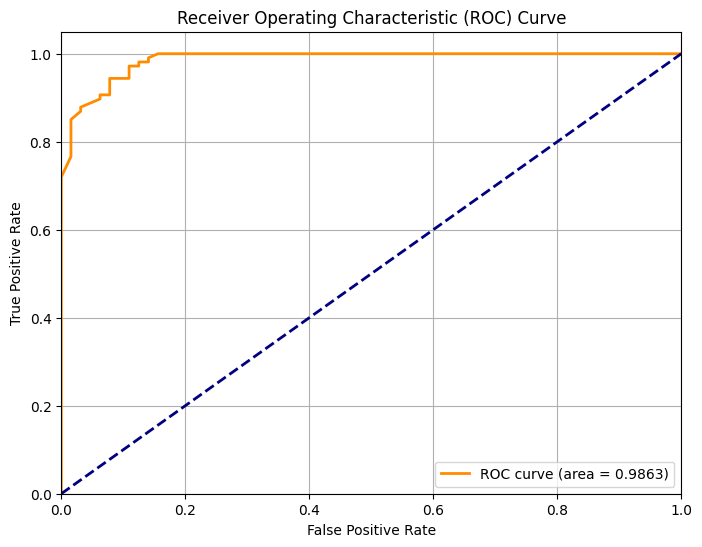

In [44]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, auc
from sklearn.pipeline import Pipeline

# 1. Load the dataset
# Why: Breast cancer dataset provides standard dimensions for evaluating classifiers
data = load_breast_cancer()
X = data.data
y = data.target

# 2. Split into train and test sets
# Why: Splitting allows us to evaluate generalizability on unseen data and prevent overfitting
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# 3. Build the pipeline containing scaling, embedded feature selection, and classification
# Why: Keeps the evaluation clean, leakage-free, and straightforward
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('feature_selection', SelectFromModel(RandomForestClassifier(n_estimators=100, random_state=42))),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))
])

# 4. Train the pipeline on the training set
pipeline.fit(X_train, y_train)

# 5. Make predictions and generate probability estimates on test data
y_pred = pipeline.predict(X_test)
y_proba = pipeline.predict_proba(X_test)[:, 1]

# 6. Evaluate metrics
accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
report = classification_report(y_test, y_pred, target_names=data.target_names)

print("=== Model Evaluation ===")
print(f"Prediction Accuracy: {accuracy:.4f}\n")
print("Confusion Matrix:")
print(cm)
print("\nClassification Report:")
print(report)

# 7. Compute and plot ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

### Comparing Pipeline Performance With and Without Feature Selection

To understand the true impact of our feature selection step, we will train a baseline pipeline using all 30 features (Standardization + Classifier) and compare its metrics directly against the feature-selected pipeline.

In [46]:
# 1. Build a baseline pipeline without any feature selection
pipeline_no_fs = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))
])

# 2. Train the baseline model
pipeline_no_fs.fit(X_train, y_train)

# 3. Generate predictions and probability scores for baseline model
y_pred_no_fs = pipeline_no_fs.predict(X_test)
y_proba_no_fs = pipeline_no_fs.predict_proba(X_test)[:, 1]

# 4. Calculate metrics for baseline model
accuracy_no_fs = accuracy_score(y_test, y_pred_no_fs)
cm_no_fs = confusion_matrix(y_test, y_pred_no_fs)
roc_auc_no_fs = auc(*roc_curve(y_test, y_proba_no_fs)[:2])

# 5. Extract original and selected feature counts
total_features = X.shape[1]
selected_features_count = pipeline.named_steps['feature_selection'].transform(X_train).shape[1]

# 6. Display a comparative summary side-by-side
print("===========================================================")
print("              PERFORMANCE COMPARISON                       ")
print("===========================================================")
print(f"{ 'Metric':<25} | { 'With Feature Selection':<22} | { 'Without Feature Selection':<22}")
print("-" * 75)
print(f"{ 'Number of Features':<25} | {selected_features_count:<22} | {total_features:<22}")
print(f"{ 'Accuracy':<25} | {f'{accuracy:.4f}':<22} | {f'{accuracy_no_fs:.4f}':<22}")
print(f"{ 'ROC-AUC':<25} | {f'{roc_auc:.4f}':<22} | {f'{roc_auc_no_fs:.4f}':<22}")
print(f"{ 'False Positives':<25} | {cm[0, 1]:<22} | {cm_no_fs[0, 1]:<22}")
print(f"{ 'False Negatives':<25} | {cm[1, 0]:<22} | {cm_no_fs[1, 0]:<22}")
print("===========================================================")

              PERFORMANCE COMPARISON                       
Metric                    | With Feature Selection | Without Feature Selection
---------------------------------------------------------------------------
Number of Features        | 9                      | 30                    
Accuracy                  | 0.9415                 | 0.9357                
ROC-AUC                   | 0.9863                 | 0.9913                
False Positives           | 7                      | 6                     
False Negatives           | 3                      | 5                     
